# Digital Restoration of Heritage Paintings — CNN training notebook

This notebook prepares patch images from the ArtInsight polygon annotations, trains a binary CNN, evaluates it, saves `artinsight_damage_cnn_final.keras`, and downloads the model for the Flask website.

**Important notes**
- Upload the ArtInsight ZIP containing the images and JSON annotation files when prompted.
- Class names are alphabetically ordered by Keras: `damaged` is class 0 and `not_damaged` is class 1. The Flask backend supplied with this notebook handles that mapping.
- This is patch-level classification, not a pixel-level damage segmentation model.
- The split below is grouped by source painting to reduce train/validation/test leakage. Results still need careful interpretation because the dataset has few original paintings.


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Project folder: C:\Users\Shree\OneDrive\Desktop\Deep_Learning_Mini_Project\heritage_restoration_app
Dataset folder: C:\Users\Shree\OneDrive\Desktop\Deep_Learning_Mini_Project\heritage_restoration_app\Dataset
TensorFlow version: 2.21.0
Images found: 20
JSON files found: 4
JSON: stucco\test\stucco_test.json
JSON: stucco\train\stucco_train.json
JSON: lpl\test\lpl_test.json
JSON: lpl\train\lpl_train.json
Annotation records matched: 20
Images with annotations: 20
Usable damage polygons: 1992
Damaged patches: 1992
Non-damaged patches: 480
Source paintings: 20
train: damaged=1001, not_damaged=270, paintings=11
val: damaged=106, not_damaged=90, paintings=3
test: damaged=885, not_damaged=120, paintings=6
Found 1271 files belonging to 2 classes.
Class mapping: {'damaged': 0, 'not_damaged': 1}
Found 196 files belonging to 2 classes.
Found 1005 files belonging to 2 classes.
Training class weights: {0: 0.6348651348651349, 1: 2.3537037037037036}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation (RandomRotation)     │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom (RandomZoom)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 421,441 (1.61 MB)

 Trainable params: 421,441 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


C:\Users\Shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6853 - loss: 0.6665 - precision: 0.3367 - recall: 0.4963
Epoch 1: val_loss improved from None to 0.79735, saving model to C:\Users\Shree\OneDrive\Desktop\Deep_Learning_Mini_Project\heritage_restoration_app\models\best_artinsight_cnn.keras

Epoch 1: finished saving model to C:\Users\Shree\OneDrive\Desktop\Deep_Learning_Mini_Project\heritage_restoration_app\models\best_artinsight_cnn.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 133s 3s/step - accuracy: 0.6853 - loss: 0.6665 - precision: 0.3367 - recall: 0.4963 - val_accuracy: 0.5051 - val_loss: 0.7974 - val_precision: 0.4790 - val_recall: 0.8889 - learning_rate: 0.0010
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8104 - loss: 0.4979 - precision: 0.5358 - recall: 0.8037
Epoch 2: val_loss did not improve from 0.79735
40/40 ━━━━━━━━━━━━━━━━━━━━ 118s 3s/step - accuracy: 0.8104 - loss: 0.4979 - precision: 0.5358 - recall: 0.8037 - val_accuracy: 0.5612 - val_loss: 0.7990 - val_precision

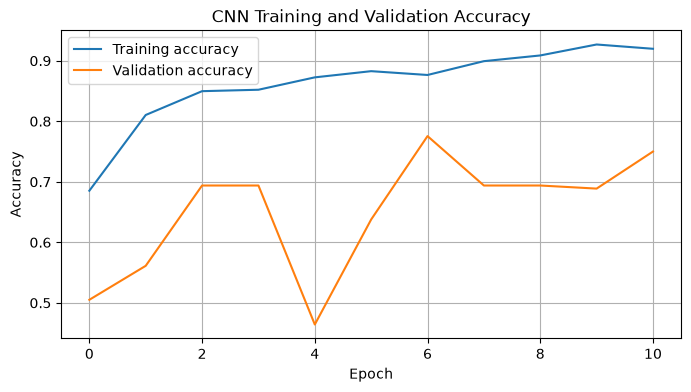

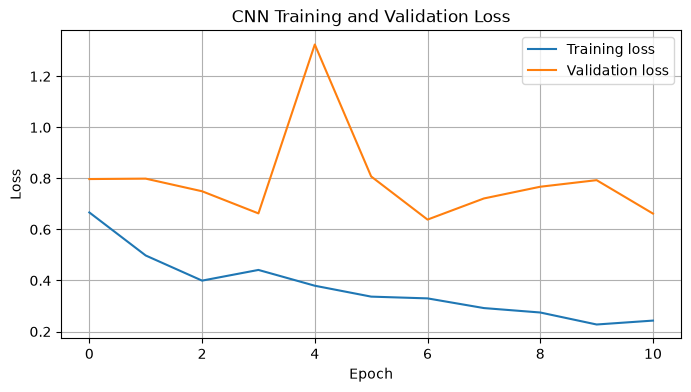


Test evaluation:
32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 709ms/step - accuracy: 0.8199 - loss: 0.4489 - precision: 0.3899 - recall: 0.9000
{'accuracy': 0.8199005126953125, 'loss': 0.44893011450767517, 'precision': 0.38989168405532837, 'recall': 0.8999999761581421}

Classification report:
              precision    recall  f1-score   support

     damaged     0.9835    0.8090    0.8878       885
 not_damaged     0.3899    0.9000    0.5441       120

    accuracy                         0.8199      1005
   macro avg     0.6867    0.8545    0.7159      1005
weighted avg     0.9126    0.8199    0.8467      1005



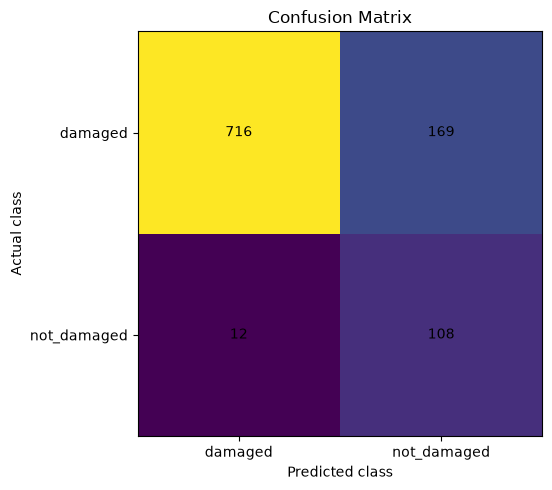


Model saved successfully:
C:\Users\Shree\OneDrive\Desktop\Deep_Learning_Mini_Project\heritage_restoration_app\models\artinsight_damage_cnn_final.keras
Model verification successful.
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)

TRAINING PIPELINE FINISHED
Next: restart Flask and check http://127.0.0.1:5000/api/health


In [1]:

# ============================================================
# DIGITAL RESTORATION OF HERITAGE PAINTINGS
# ArtInsight dataset -> CNN training -> save model for Flask
# For VS Code Jupyter Notebook on Windows
# ============================================================

%pip install tensorflow numpy pandas pillow matplotlib scikit-learn

import os
import json
import math
import random
import shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# ------------------------------------------------------------
# 1. PROJECT AND DATASET PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\Shree\OneDrive\Desktop\Deep_Learning_Mini_Project\heritage_restoration_app"
)

DATASET_DIR = PROJECT_DIR / "Dataset"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset folder was not found:\n{DATASET_DIR}\n"
        "Check the folder name and path."
    )

print("Project folder:", PROJECT_DIR)
print("Dataset folder:", DATASET_DIR)
print("TensorFlow version:", tf.__version__)

# ------------------------------------------------------------
# 2. FIND IMAGES AND JSON ANNOTATIONS
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

json_files = [
    p for p in DATASET_DIR.rglob("*.json")
    if p.is_file()
]

print("Images found:", len(image_files))
print("JSON files found:", len(json_files))

for p in json_files:
    print("JSON:", p.relative_to(DATASET_DIR))

if not image_files:
    raise ValueError(
        "No images found inside Dataset. Check its contents."
    )

if not json_files:
    raise ValueError(
        "No JSON annotation files found inside Dataset."
    )

# Index images by filename. If filenames repeat, retain all paths.
image_lookup = defaultdict(list)
for p in image_files:
    image_lookup[p.name.lower()].append(p)

# ------------------------------------------------------------
# 3. READ ANNOTATION JSON FILES
# Supports common VIA-style polygon annotations.
# ------------------------------------------------------------

def read_json(path):
    with open(path, "r", encoding="utf-8-sig") as f:
        return json.load(f)


def extract_entries(data):
    """Return likely image annotation records from JSON."""
    if isinstance(data, list):
        return [x for x in data if isinstance(x, dict)]

    if not isinstance(data, dict):
        return []

    # VIA project files often contain a _via_img_metadata dictionary.
    for key in ("_via_img_metadata", "images", "annotations"):
        value = data.get(key)
        if isinstance(value, dict):
            return [
                x for x in value.values()
                if isinstance(x, dict)
            ]
        if isinstance(value, list):
            return [
                x for x in value
                if isinstance(x, dict)
            ]

    # Some files directly map image IDs to records.
    if any("filename" in v for v in data.values()
           if isinstance(v, dict)):
        return [
            v for v in data.values()
            if isinstance(v, dict) and "filename" in v
        ]

    # A single annotation record.
    if "filename" in data:
        return [data]

    return []


def get_regions(entry):
    regions = entry.get("regions", [])

    if isinstance(regions, dict):
        regions = list(regions.values())

    if not isinstance(regions, list):
        return []

    return regions


def get_polygon(region):
    shape = region.get("shape_attributes", {}) or {}

    xs = shape.get("all_points_x", [])
    ys = shape.get("all_points_y", [])

    if not isinstance(xs, (list, tuple)):
        return None
    if not isinstance(ys, (list, tuple)):
        return None
    if len(xs) < 3 or len(xs) != len(ys):
        return None

    try:
        points = [(float(x), float(y)) for x, y in zip(xs, ys)]
    except (TypeError, ValueError):
        return None

    return points


damage_annotations = defaultdict(list)
source_split_hint = {}
unmatched_annotation_names = set()
records_read = 0

for json_path in json_files:
    try:
        data = read_json(json_path)
    except Exception as e:
        print("Could not read JSON:", json_path.name, e)
        continue

    entries = extract_entries(data)

    if not entries:
        print("No recognizable image records in:", json_path.name)
        continue

    json_name = json_path.name.lower()
    split_hint = "test" if "test" in json_name else "train"

    for entry in entries:
        filename = entry.get("filename")

        if not filename:
            continue

        # Match filename, including common Windows/Unix path separators.
        filename = str(filename).replace("\\", "/").split("/")[-1]
        candidates = image_lookup.get(filename.lower(), [])

        if not candidates:
            unmatched_annotation_names.add(filename)
            continue

        # If duplicate names exist, choose the first match.
        image_path = candidates[0]
        actual_name = image_path.name
        records_read += 1

        for region in get_regions(entry):
            polygon = get_polygon(region)
            if polygon is not None:
                damage_annotations[str(image_path)].append(polygon)

        if (
            actual_name not in source_split_hint
            or split_hint == "test"
        ):
            source_split_hint[actual_name] = split_hint

print("Annotation records matched:", records_read)
print("Images with annotations:", len(damage_annotations))
print(
    "Usable damage polygons:",
    sum(len(v) for v in damage_annotations.values())
)

if unmatched_annotation_names:
    print(
        "Annotation filenames not matched:",
        list(sorted(unmatched_annotation_names))[:10]
    )

if not damage_annotations:
    raise ValueError(
        "No annotations matched your images. The JSON format or "
        "image filenames differ from the expected format. "
        "Check the JSON filenames and the printed diagnostics."
    )

# ------------------------------------------------------------
# 4. GENERATE DAMAGED AND NON-DAMAGED IMAGE PATCHES
# ------------------------------------------------------------

PATCH_SIZE = 224
MAX_NEGATIVES_PER_IMAGE = 30
SEED = 42

random.seed(SEED)
rng = random.Random(SEED)

PATCH_DIR = PROJECT_DIR / "generated_patches_tmp"
DATASET_ROOT = PROJECT_DIR / "cnn_dataset_grouped"

for folder in (PATCH_DIR, DATASET_ROOT):
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True, exist_ok=True)

for split in ("train", "val", "test"):
    for class_name in ("damaged", "not_damaged"):
        (DATASET_ROOT / split / class_name).mkdir(
            parents=True, exist_ok=True
        )

samples_by_source = defaultdict(list)


def overlaps(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    return not (
        ax2 <= bx1 or ax1 >= bx2
        or ay2 <= by1 or ay1 >= by2
    )


for source_path_str, polygons in damage_annotations.items():
    source_path = Path(source_path_str)

    try:
        image = Image.open(source_path).convert("RGB")
    except Exception as e:
        print("Skipping unreadable image:", source_path.name, e)
        continue

    width, height = image.size
    boxes = []

    for polygon in polygons:
        xs = [point[0] for point in polygon]
        ys = [point[1] for point in polygon]

        x1 = max(0, min(width, int(math.floor(min(xs)))))
        y1 = max(0, min(height, int(math.floor(min(ys)))))
        x2 = max(0, min(width, int(math.ceil(max(xs)))))
        y2 = max(0, min(height, int(math.ceil(max(ys)))))

        if x2 > x1 and y2 > y1:
            boxes.append((x1, y1, x2, y2))

    # Positive patches: bounding boxes around annotated damage.
    for idx, box in enumerate(boxes):
        x1, y1, x2, y2 = box

        if x2 - x1 < 5 or y2 - y1 < 5:
            continue

        crop = image.crop(box).resize((PATCH_SIZE, PATCH_SIZE))
        out = PATCH_DIR / (
            f"{source_path.stem}_damage_{idx}_{len(samples_by_source[source_path.name])}.jpg"
        )
        crop.save(out, quality=95)
        samples_by_source[source_path.name].append(
            (out, "damaged")
        )

    # Negative patches: crop regions not overlapping annotated boxes.
    side = min(PATCH_SIZE, width, height)

    if side < 20:
        continue

    generated = 0
    attempts = 0
    max_attempts = MAX_NEGATIVES_PER_IMAGE * 100

    while (
        generated < MAX_NEGATIVES_PER_IMAGE
        and attempts < max_attempts
    ):
        attempts += 1

        x = rng.randint(0, max(0, width - side))
        y = rng.randint(0, max(0, height - side))
        candidate = (x, y, x + side, y + side)

        if any(overlaps(candidate, box) for box in boxes):
            continue

        crop = image.crop(candidate).resize((PATCH_SIZE, PATCH_SIZE))
        out = PATCH_DIR / (
            f"{source_path.stem}_normal_{generated}_{len(samples_by_source[source_path.name])}.jpg"
        )
        crop.save(out, quality=95)

        samples_by_source[source_path.name].append(
            (out, "not_damaged")
        )
        generated += 1

damaged_count = sum(
    label == "damaged"
    for samples in samples_by_source.values()
    for _, label in samples
)
normal_count = sum(
    label == "not_damaged"
    for samples in samples_by_source.values()
    for _, label in samples
)

print("Damaged patches:", damaged_count)
print("Non-damaged patches:", normal_count)
print("Source paintings:", len(samples_by_source))

if damaged_count == 0 or normal_count == 0:
    raise ValueError(
        "Could not generate both classes. Check polygon annotations "
        "and source images."
    )

# ------------------------------------------------------------
# 5. SPLIT BY ORIGINAL PAINTING
# Avoid putting patches from the same painting in multiple splits.
# ------------------------------------------------------------

source_names = list(samples_by_source.keys())

test_sources = [
    name for name in source_names
    if source_split_hint.get(name) == "test"
]
other_sources = [
    name for name in source_names
    if name not in test_sources
]

rng.shuffle(other_sources)

# If JSON filenames do not identify a test set, hold out some paintings.
if not test_sources and len(source_names) >= 5:
    n_test = max(1, round(0.15 * len(source_names)))
    test_sources = other_sources[:n_test]
    other_sources = other_sources[n_test:]

if len(other_sources) >= 3:
    train_sources, val_sources = train_test_split(
        other_sources,
        test_size=0.20,
        random_state=SEED
    )
else:
    train_sources = other_sources
    val_sources = []

if not train_sources:
    raise ValueError(
        "No training paintings remain after splitting. "
        "Check the number of annotated paintings."
    )

split_sources = {
    "train": train_sources,
    "val": val_sources,
    "test": test_sources
}

for split, sources in split_sources.items():
    for source in sources:
        for source_file, class_name in samples_by_source[source]:
            destination = (
                DATASET_ROOT / split / class_name / source_file.name
            )
            shutil.copy2(source_file, destination)

for split in ("train", "val", "test"):
    d = len(list((DATASET_ROOT / split / "damaged").glob("*.jpg")))
    n = len(list((DATASET_ROOT / split / "not_damaged").glob("*.jpg")))
    print(f"{split}: damaged={d}, not_damaged={n}, paintings={len(split_sources[split])}")

# Temporary files are no longer needed.
shutil.rmtree(PATCH_DIR, ignore_errors=True)

# ------------------------------------------------------------
# 6. LOAD IMAGE DATASETS
# Class order is alphabetical:
# damaged = 0, not_damaged = 1
# ------------------------------------------------------------

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_dir = DATASET_ROOT / "train"
val_dir = DATASET_ROOT / "val"
test_dir = DATASET_ROOT / "test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    str(train_dir),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

class_names = train_ds.class_names
print("Class mapping:", {name: i for i, name in enumerate(class_names)})

if class_names != ["damaged", "not_damaged"]:
    raise ValueError(
        f"Unexpected class order: {class_names}. "
        "Expected ['damaged', 'not_damaged']."
    )


def has_both_classes(folder):
    return all(
        any((folder / name).glob("*.jpg"))
        for name in ("damaged", "not_damaged")
    )


if has_both_classes(val_dir):
    validation_ds = tf.keras.utils.image_dataset_from_directory(
        str(val_dir),
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        shuffle=False
    )
else:
    print(
        "WARNING: Validation paintings do not contain both classes. "
        "Using a patch-level validation split for training diagnostics."
    )
    train_ds = tf.keras.utils.image_dataset_from_directory(
        str(train_dir),
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        validation_split=0.2,
        subset="training",
        seed=SEED
    )
    validation_ds = tf.keras.utils.image_dataset_from_directory(
        str(train_dir),
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        validation_split=0.2,
        subset="validation",
        seed=SEED
    )

test_ds = None
if has_both_classes(test_dir):
    test_ds = tf.keras.utils.image_dataset_from_directory(
        str(test_dir),
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        shuffle=False
    )
else:
    print(
        "WARNING: No held-out test set containing both classes. "
        "Final test metrics will not be calculated."
    )


def normalize_images(images, labels):
    return tf.cast(images, tf.float32) / 255.0, labels


train_ds = train_ds.map(
    normalize_images, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

validation_ds = validation_ds.map(
    normalize_images, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

if test_ds is not None:
    test_ds = test_ds.map(
        normalize_images, num_parallel_calls=AUTOTUNE
    ).prefetch(AUTOTUNE)

# ------------------------------------------------------------
# 7. CALCULATE CLASS WEIGHTS
# ------------------------------------------------------------

train_labels = []
for _, labels in train_ds:
    train_labels.extend(
        labels.numpy().astype(int).reshape(-1).tolist()
    )

classes_present = np.unique(train_labels)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_present,
    y=np.array(train_labels)
)

class_weight = {
    int(cls): float(weight)
    for cls, weight in zip(classes_present, weights)
}
print("Training class weights:", class_weight)

# ------------------------------------------------------------
# 8. BUILD CNN
# Output meaning: sigmoid probability for class 1 (not_damaged)
# ------------------------------------------------------------

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),

    tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(256, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

# ------------------------------------------------------------
# 9. TRAIN MODEL AND SAVE BEST CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = MODEL_DIR / "best_artinsight_cnn.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=20,
    callbacks=callbacks,
    class_weight=class_weight
)

if checkpoint_path.exists():
    model = tf.keras.models.load_model(checkpoint_path)

# ------------------------------------------------------------
# 10. PLOT TRAINING HISTORY
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))
plt.plot(history.history.get("accuracy", []), label="Training accuracy")
plt.plot(history.history.get("val_accuracy", []), label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history.get("loss", []), label="Training loss")
plt.plot(history.history.get("val_loss", []), label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# 11. EVALUATE ON HELD-OUT TEST PAINTINGS, IF AVAILABLE
# ------------------------------------------------------------

if test_ds is not None:
    print("\nTest evaluation:")
    print(model.evaluate(test_ds, return_dict=True, verbose=1))

    y_true = []
    y_pred = []

    for images, labels in test_ds:
        probabilities = model.predict(images, verbose=0).reshape(-1)
        y_true.extend(labels.numpy().astype(int).reshape(-1).tolist())
        y_pred.extend((probabilities >= 0.5).astype(int).tolist())

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["damaged", "not_damaged"],
        zero_division=0,
        digits=4
    ))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(6, 5))
    plt.imshow(cm)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.xticks([0, 1], ["damaged", "not_damaged"])
    plt.yticks([0, 1], ["damaged", "not_damaged"])

    for (i, j), value in np.ndenumerate(cm):
        plt.text(j, i, str(value), ha="center", va="center")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 12. SAVE FINAL MODEL FOR YOUR FLASK APP
# ------------------------------------------------------------

FINAL_MODEL_PATH = MODEL_DIR / "artinsight_damage_cnn_final.keras"
model.save(FINAL_MODEL_PATH)

print("\nModel saved successfully:")
print(FINAL_MODEL_PATH)

# Verify saved model can be loaded.
check_model = tf.keras.models.load_model(FINAL_MODEL_PATH)

print("Model verification successful.")
print("Input shape:", check_model.input_shape)
print("Output shape:", check_model.output_shape)
print("\nTRAINING PIPELINE FINISHED")
print("Next: restart Flask and check http://127.0.0.1:5000/api/health")
